# Imacec minero de Chile
Serie mensual enero de 2013–agosto de 2026, índice empalmado con base promedio 2018 = 100.

**Antes de ejecutar:**
1. `Entorno de ejecución → Cambiar tipo de entorno de ejecución → R`.
2. Abre el panel de archivos (ícono de carpeta a la izquierda) y sube `CCNN2018_IMACEC_01_A (Mineria).xlsx`.
3. `Entorno de ejecución → Ejecutar todas`.

## 1. Preguntas iniciales



1.   ¿Cuál es la frecuencia de la serie? La serie tiene una frecuencia mensual
2.   ¿En qué unidad está medida (tasa en %, índice u otra)? La serie corresponde a un indice de actividad económica con base en el prmedio del 2018 = 100


1.   ¿Desde que fecha hay datos? La serie presenta datos desde Enero 2013






## 2. Paquetes

In [28]:
# Colab (R) ya trae tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl); library(dplyr); library(ggplot2); library(scales); library(tidyr)
})

## 3. Lectura y limpieza de datos
La hoja `Cuadro` trae el título en la fila 1 y los encabezados en la fila 3, por eso se saltan 2 filas. La serie es mensual y está expresada como un índice con base promedio 2018 = 100.

In [29]:
archivo <- list.files(c("/content", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el .xlsx. Súbelo desde el panel de archivos (ícono de carpeta).")
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(fecha = as.Date(fecha), indice = as.numeric(indice)) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha) |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1/12, 12), sides = 1)),  # promedio móvil 12 meses
    var_12m   = (indice / lag(indice, 12) - 1) * 100                         # variación porcentual vs. año anterior
  )

cat("Observaciones:", nrow(df), "\n")
summary(df$indice)
tail(df)

Leyendo: ./CCNN2018_IMACEC_01_A (Mineria).xlsx 
Observaciones: 164 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  69.93   88.25   94.66   93.65   99.59  115.70 

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2026-03-01,83.92646,2026,3,89.47111,-7.373713
2026-04-01,80.60050,2026,4,88.48665,-12.783173
2026-05-01,86.16983,2026,5,87.43859,-12.736415
2026-06-01,89.37930,2026,6,88.00475,8.226491
2026-07-01,77.60130,2026,7,87.34185,-9.297672
2026-08-01,69.93090,2026,8,86.11673,-17.370917


## 4. Justificación de la variación en 12 meses
La serie estudiada se expresada como un índice de actividad económica, por lo que no puede ser interpretada como un porcentaje y/o una tasa. Por esta razón, la variación respecto del mismo mes del año anterior se debería calcular de la forma: `(indice / lag(indice, 12) - 1) * 100`.

Esta expresión mide el cambio porcentual relativo entre los diferentes niveles del índice. No se utiliza una diferencia en puntos porcentuales, porque los valores del índice no están representados como porcentajes, y tratarlos como tal, afecta directamente en la interpretación de los datos.
Se hace uso de la función lag ya que esta permite acceder a valores anteriores para compararlos con el valor actual, permitiendo la óptima comparación de la seria en distintos periodos.

## 5. Estilo común para los gráficos

In [30]:
# Crea un vector con las abreviaturas de los 12 meses en español
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
# Crea una función que convierte una fecha en una etiqueta tipo "Ago 2026"
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
# Crea una función que formatea números
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # azul
col_acento    <- "#E07B39"   # naranjo

# estilo visual común
tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title         = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle      = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption       = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position    = "top", legend.justification = "left",
    plot.background    = element_rect(fill = "white", colour = NA),
    plot.margin        = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: Banco Central de Chile, Base de Datos Estadísticos. Serie F032.IMC.IND.Z.Z.EP18.03.Z.0.M (Imacec minero, índice 2018 = 100)."

## 6. Evolución del Imacec minero
Serie mensual, promedio móvil de 12 meses, período de pandemia sombreado y marcas en el máximo, el mínimo y el último dato.

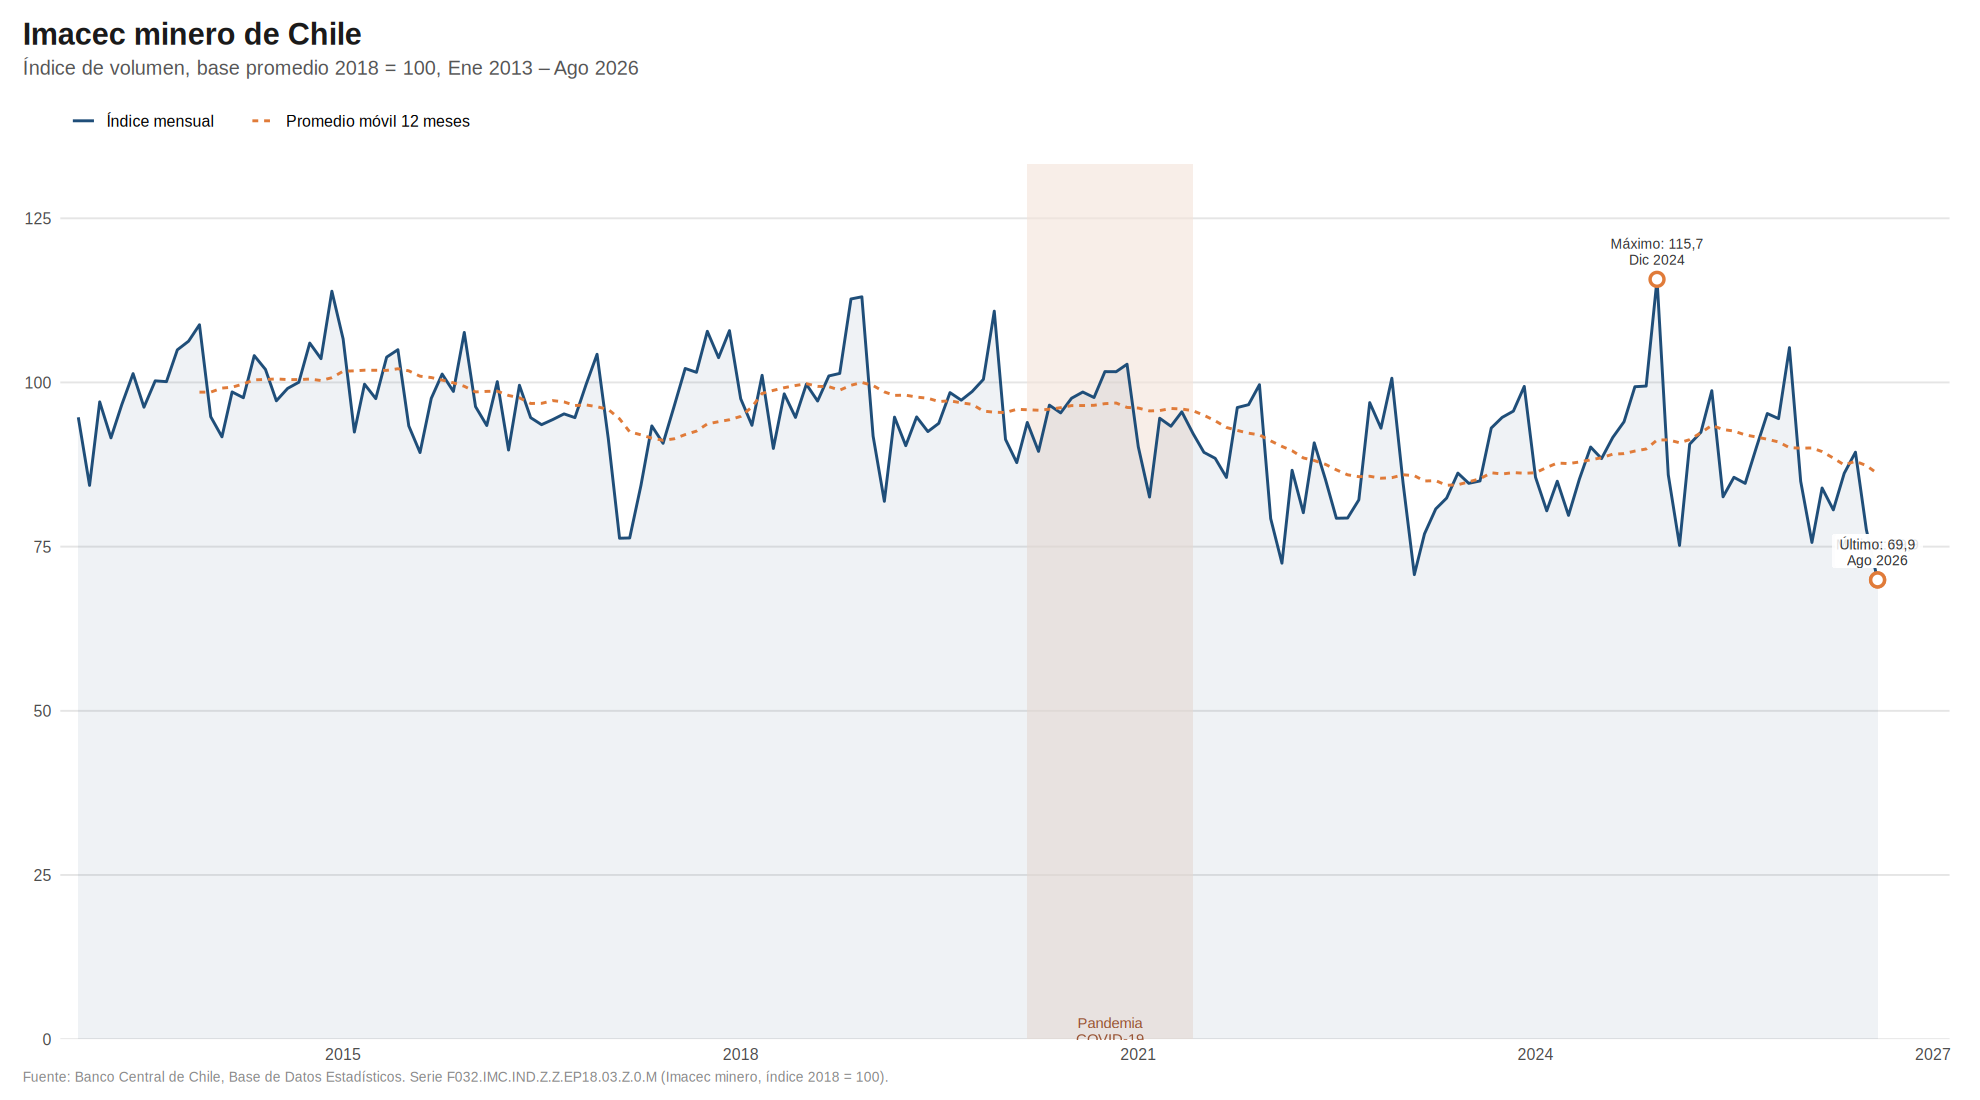

In [31]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# arma una pequeña tabla llamada hitos con los tres puntos que se destacan en el primer gráfico: el máximo, el mínimo y el último dato.
hitos <- bind_rows(
  df |> slice_max(indice, n = 1) |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_min(indice, n = 1) |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1)      |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)))
)

# construye el gráfico (la serie de tiempo) y lo guarda como g1
g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2020-10-15"), y = 1.2, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_area(aes(y = indice), fill = col_principal, alpha = .07) +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = indice, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Índice mensual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "3 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .04))) +
  scale_y_continuous(labels = label_number(accuracy = 1),
                     limits = c(0, max(df$indice) + 15), expand = expansion(mult = c(0, .02))) +
  labs(title = "Imacec minero de Chile",
       subtitle = paste0("Índice de volumen, base promedio 2018 = 100, ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = NULL, caption = fuente) +
  tema

g1

## 7. Mapa de calor del Imacec minero por año y mes
Permite ver de un vistazo los años altos y bajos y el patrón estacional.

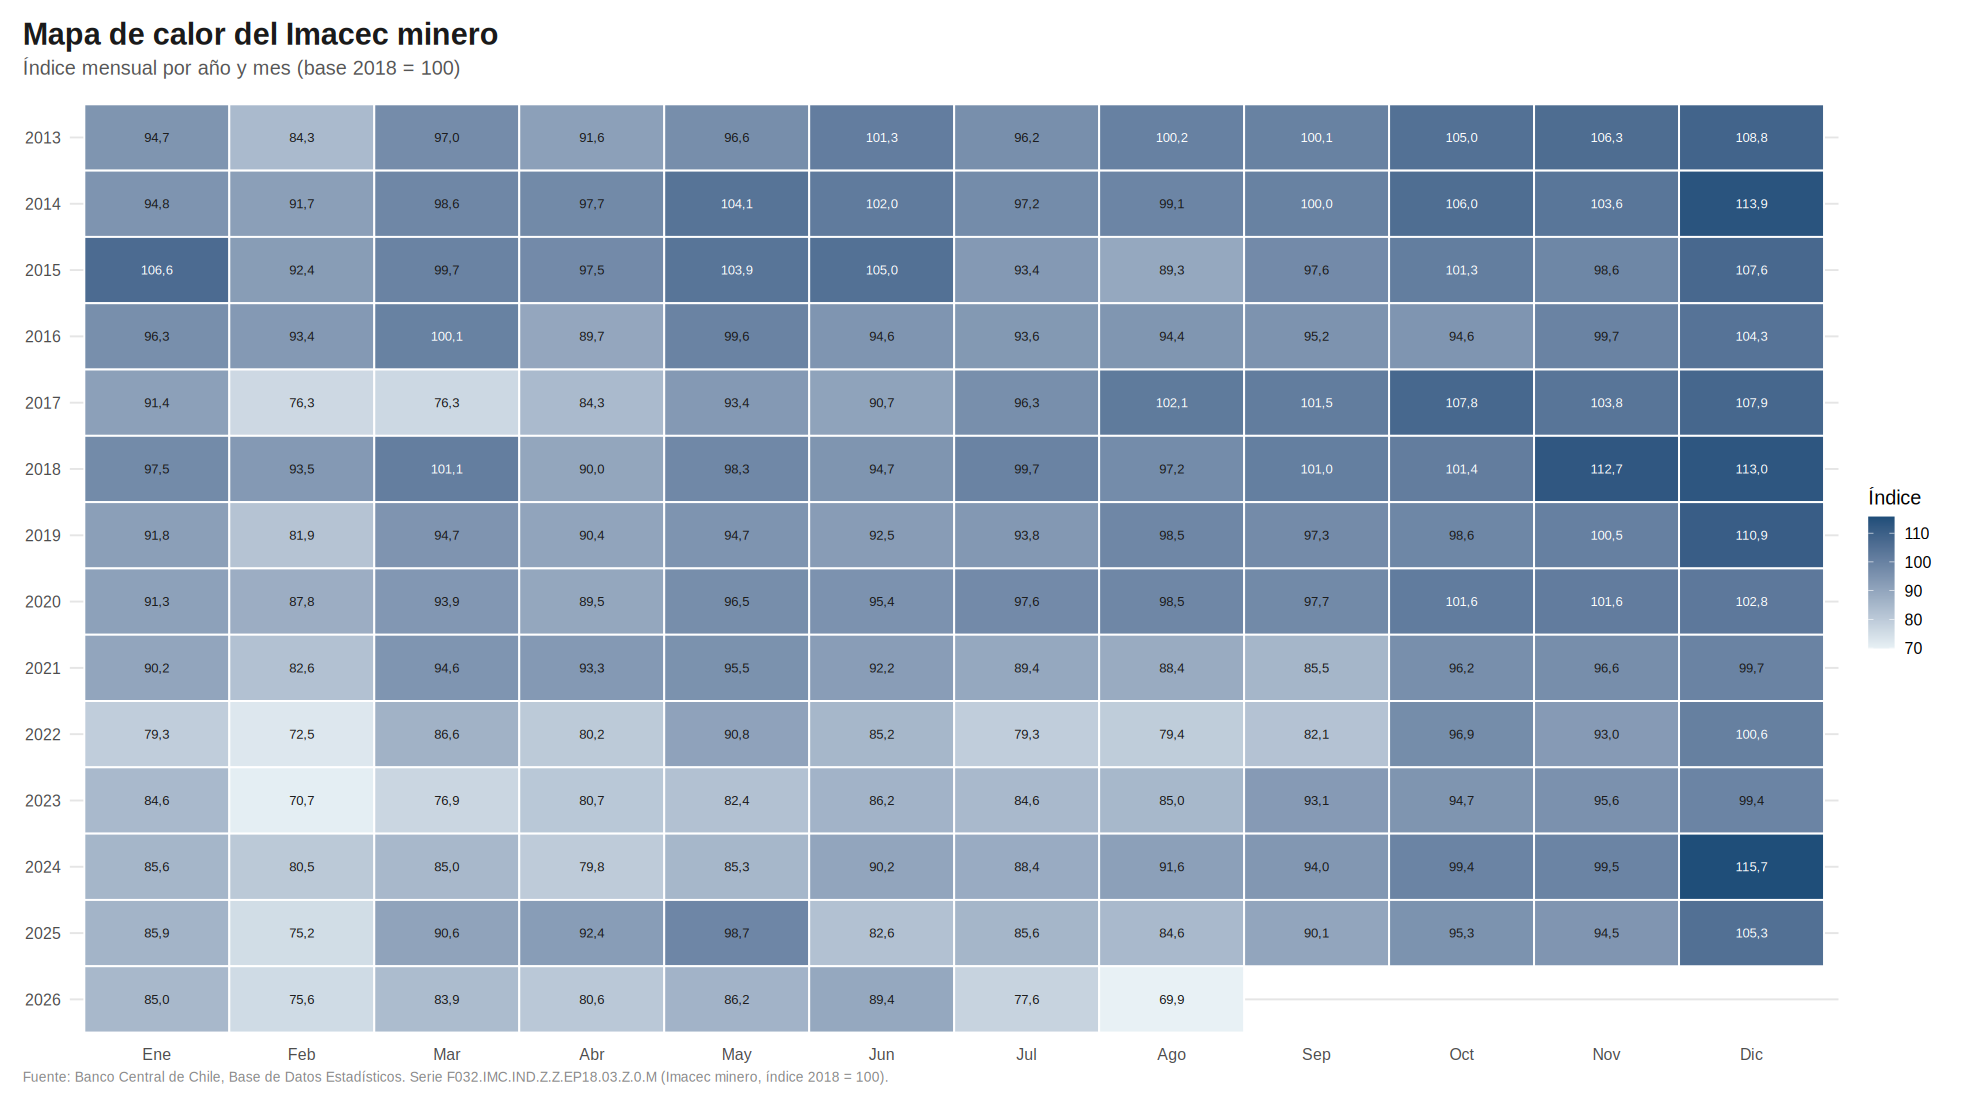

In [32]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el mapa de calor y lo guarda como g2
g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = indice)) +
  geom_tile(colour = "white", linewidth = .6) +
  geom_text(aes(label = num_es(indice), colour = indice > 100), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#E8F1F5", high = "#1F4E79", name = "Índice") +
  labs(title = "Mapa de calor del Imacec minero",
       subtitle = "Índice mensual por año y mes (base 2018 = 100)", x = NULL, y = NULL, caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

## 8. Variación porcentual en 12 meses
Cuánto subió o bajó el índice respecto del mismo mes del año anterior.

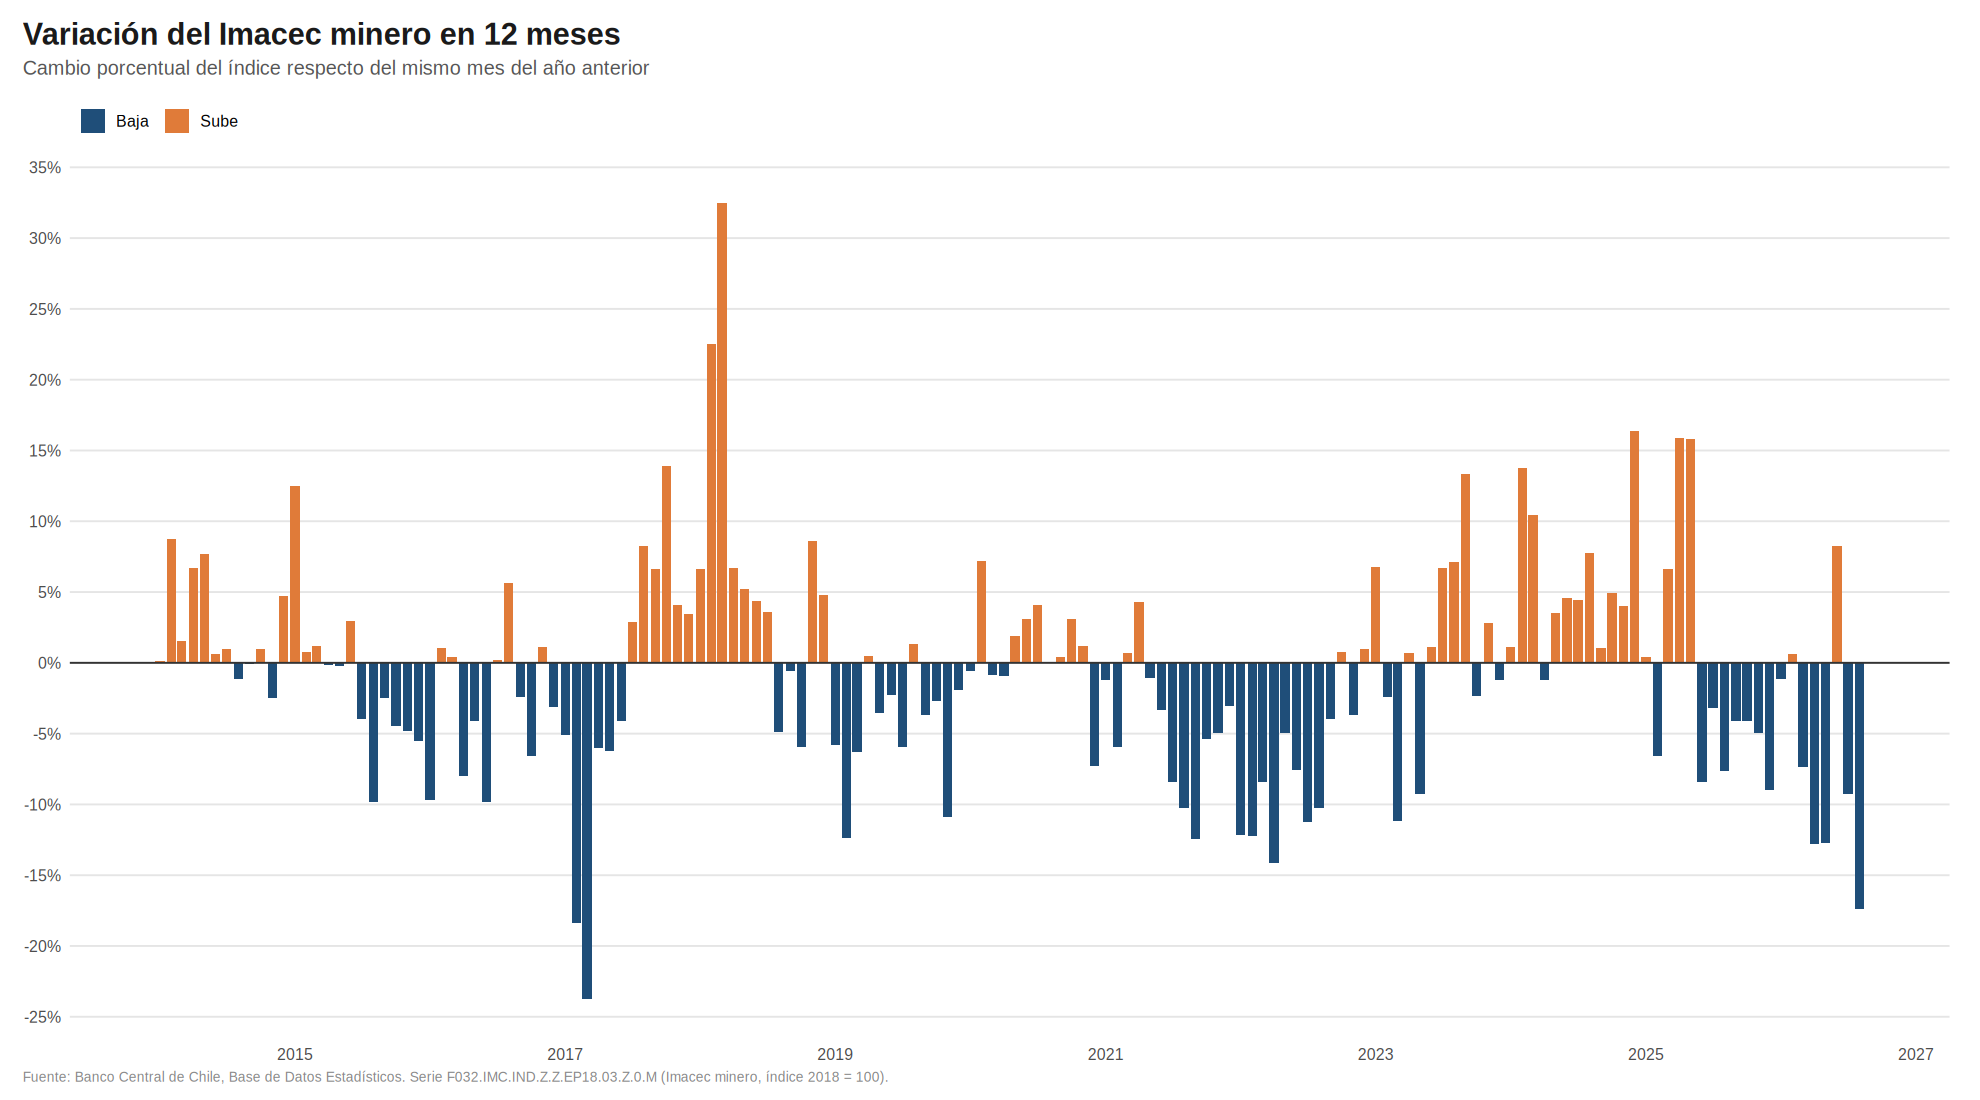

In [33]:
# define el tamaño y la resolución con que Colab muestra los gráficos en el notebook
options(repr.plot.width = 18, repr.plot.height = 10)

# construye el gráfico de barras de la variación en 12 meses y lo guarda como g3
g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(NULL, values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    labels = c(`TRUE` = "Sube", `FALSE` = "Baja")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(breaks = breaks_width(5), labels = label_number(accuracy = 1, suffix = "%")) +
  labs(title = "Variación del Imacec minero en 12 meses",
       subtitle = "Cambio porcentual del índice respecto del mismo mes del año anterior",
       x = NULL, y = NULL, caption = fuente) +
  tema

g3

## 9. Interpretación de los resultados
De los datos observados se puede concluir que el Imacec minero tiene un promedio de 93,65 durante el período enero de 2013 a agosto de 2026. El último dato registrado, en agosto de 2026, tiene un valor de 69,93, ubicándose 23,72 puntos por debajo del promedio del período. Además, el valor reciente es inferior al promedio móvil del último año, que es aproximadamente 86,12, lo que sugiere un debilitamiento la actividad minera.

El máximo de la serie fue registrado en diciembre de 2024, con un índice de 115,70, asociandose a una mayor producción minera en el final del mismo año, especialmente en el sector del cobre, sin embargo, este dato puede asociarse también a factores estacionales no considerados en el estudio estadistico.
El valor mínimo se registra en agosto de 2026, con un índice de 69,93, debido a lo reciente de dicha cifra, es importante considerar factores externos a la producción minera para su correcto análisis (como factores climáticos o fenómenos naturales que podrían explicar el nivel), aun que, siendo la mas baja y siguiendo la tendencia, se podría decir que indica una baja cosntante en la actividad económica minera en Chile.

El mapa de calor muestra que diciembre es en promedio el mes con un mayor índice, con aproximadamente 106,91, por otro lado, febrero es el menor con 82,75. También se observan altos niveles durante octubre y noviembre. El comportamiento de las cifras se repite en el tiempo, por lo tanto, estos datos pueden relacionarse con factores estacionarios y tendencias económicas en el país.

La variación en doce meses dobre la tendencia actual muestra que en agosto de 2026 el índice disminuyó respecto de agosto de 2025, este resultado, y el hecho de que el último valor se encuentra por debajo del promedio móvil del último año, indica que la tendencia reciente es negativa y que la caída no puede ser explicada por cambios mensuales aislados.

## 10. Guardar los gráficos en PNG
Quedan en el panel de archivos; clic derecho → Descargar.

In [34]:
ggsave("imacec_minero_serie.png",       g1, width = 12, height = 6.5, dpi = 300)
ggsave("imacec_minero_mapa_calor.png",  g2, width = 11, height = 8,   dpi = 300)
ggsave("imacec_minero_variacion12m.png", g3, width = 12, height = 5.5, dpi = 300)
list.files(pattern = "\\.png$")

[1] "imacec_minero_mapa_calor.png"   "imacec_minero_serie.png"       
[3] "imacec_minero_variacion12m.png"